# Lesson 2 — One buried magnet: drawing pictures of the underground (Recipe B)

**Setting (Osborne-style):** a plane flies a straight line 60 m above flat ground, towing a magnetometer.
Somewhere below is a lump of **magnetite-rich ironstone**. Magnetite is magnetic, and the Earth's field magnetises it,
so the lump acts like a buried bar magnet that slightly bends the Earth's field. The plane measures that bend: the **total-field anomaly**, in nanotesla (nT).

We'll **hide** a lump ourselves, simulate noisy readings, and then pretend we don't know where it is.
Because we hid it, we can check every answer.

**Plan**
1. Build intuition for the physics: how depth and size change the readings.
2. Make a fake survey with a hidden lump.
3. Write the **score** (prior × fit to readings).
4. Get a **gold-standard** answer with slow-but-trustworthy MCMC.
5. Train a flow with **Recipe B** (`reverse_kld`) — no examples, only the score.
6. Grade the flow against MCMC and against the truth; let the flow grade itself (importance ESS).
7. Look at the "pictures", and at what the readings *can't* tell us.
8. Experiment: lie about the sensor noise and watch the flow become confidently wrong — and how to catch it.

Runs on CPU in about 5 minutes.

In [1]:
import sys, time, inspect
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # this repo's normflows

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import normflows as nf
import geomag as gm

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

## 1. The physics

A uniformly magnetised sphere looks, from outside, exactly like a tiny bar magnet at its centre. This is the whole forward model:

In [2]:
print(inspect.getsource(gm.sphere_tmi))

def sphere_tmi(x_sensors, x0, depth, radius, chi, F=50000.0, inc_deg=-50.0, h=60.0):
    """Total-field anomaly (nT) of a sphere magnetised by the Earth's field.

    A uniformly magnetised sphere looks, from outside, exactly like a tiny bar magnet (a dipole) at its centre.
    Its strength is (volume x susceptibility x Earth's field); its direction follows the Earth's field.

    Args:
      x_sensors: (n_sensors,) positions along the line
      x0, depth, radius, chi: (batch,) sphere centre position, centre depth below ground, radius, susceptibility
      F: Earth's field strength in nT (about 50,000 nT in northern Australia)
      inc_deg: field inclination; negative = field points upward (southern hemisphere)
      h: sensor height above ground

    Returns:
      (batch, n_sensors) anomaly in nT
    """
    inc = math.radians(inc_deg)
    fx, fz = math.cos(inc), math.sin(inc)            # unit vector of Earth's field (x, z-down)
    rx = x_sensors[None, :] - x0[:, None]           

Let's feel what the four numbers do. The survey line runs south→north; the Earth's field here points **upward** at 50° (southern hemisphere),
which is why each anomaly has a high on one side and a low on the other.

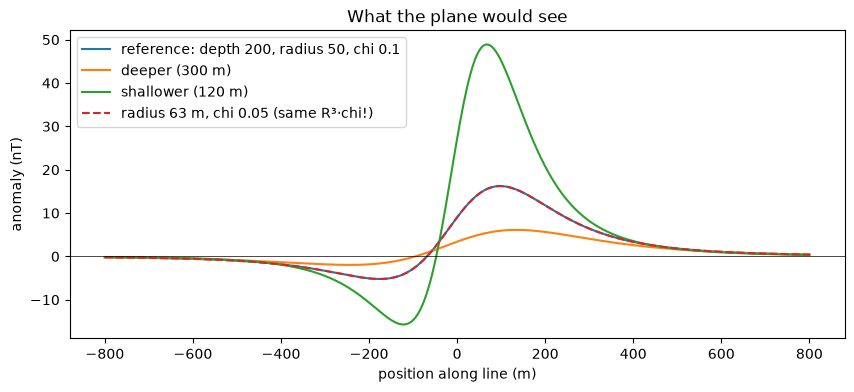

In [3]:
xs_dense = torch.linspace(-800, 800, 400)
cases = [
    ("reference: depth 200, radius 50, chi 0.1", 0, 200, 50, 0.10),
    ("deeper (300 m)", 0, 300, 50, 0.10),
    ("shallower (120 m)", 0, 120, 50, 0.10),
    ("radius 63 m, chi 0.05 (same R³·chi!)", 0, 200, 63, 0.05),
]
plt.figure(figsize=(10, 4))
for label, x0, d, r, chi in cases:
    t = lambda v: torch.tensor([float(v)])
    ls = "--" if "same" in label else "-"
    plt.plot(xs_dense, gm.sphere_tmi(xs_dense, t(x0), t(d), t(r), t(chi))[0], ls, label=label)
plt.axhline(0, color="k", lw=0.5); plt.xlabel("position along line (m)"); plt.ylabel("anomaly (nT)")
plt.legend(); plt.title("What the plane would see"); plt.show()

Three take-aways that will show up in the results:
- **Depth sets the width** — deeper lumps make wider, weaker bumps. So depth is learnable from the *shape*.
- **Radius and susceptibility only appear as `radius³ × chi`.** The dashed line lies *exactly* on the reference line:
  a bigger, weakly magnetic lump and a smaller, strongly magnetic lump are indistinguishable. No amount of data along this line can separate them.
- Amplitude also trades off against depth, but the shape partly breaks that tie.

## 2. The fake survey (we hide the lump)

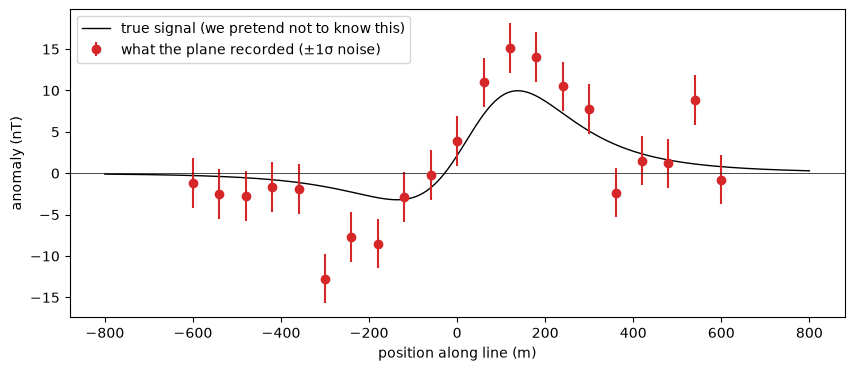

Hidden truth: {'x0': 40.0, 'depth': 200.0, 'radius': 40.0, 'chi': 0.12}


In [4]:
TRUE = dict(x0=40.0, depth=200.0, radius=40.0, chi=0.12)
theta_true = gm.phys_to_theta(**TRUE)

x_sensors = torch.linspace(-600, 600, 21)   # 21 readings, 60 m apart
NOISE = 3.0                                  # sensor + wind + everything else: 3 nT
gen = torch.Generator().manual_seed(1)
clean = gm.predict(theta_true, x_sensors)[0]
readings = clean + NOISE * torch.randn(len(x_sensors), generator=gen)

plt.figure(figsize=(10, 4))
plt.plot(xs_dense, gm.predict(theta_true, xs_dense)[0], "k-", lw=1, label="true signal (we pretend not to know this)")
plt.errorbar(x_sensors, readings, yerr=NOISE, fmt="o", color="C3", label="what the plane recorded (±1σ noise)")
plt.axhline(0, color="k", lw=0.5); plt.xlabel("position along line (m)"); plt.ylabel("anomaly (nT)")
plt.legend(); plt.show()
print("Hidden truth:", TRUE)

Peak signal ≈ 10 nT against 3 nT noise: a realistic, *hard-ish* target.

## 3. The score

The flow works with 4 unitless numbers `theta`. `geomag.theta_to_phys` maps them to physical values, and the **prior** is simply
"each theta is standard normal", which means (see `geomag.py`):

| | prior belief (≈ 90% range) |
|---|---|
| position x0 | −490 m … +490 m |
| depth | 66 m … 340 m |
| radius | 13 m … 68 m |
| susceptibility | 0.01 … 0.26 SI |

Score = **log prior** ("does it make sense?") + **log likelihood** ("does it match the readings, given 3 nT noise?"):

In [5]:
print(inspect.getsource(gm.SpherePosterior.log_prob))
posterior = gm.SpherePosterior(x_sensors, readings, NOISE)

    def log_prob(self, theta):
        pred = predict(theta, self.x_sensors, **self.physics_kw)
        log_lik = -0.5 * (((pred - self.readings) / self.noise) ** 2).sum(-1)
        log_prior = -0.5 * (theta**2).sum(-1)
        return log_lik + log_prior



## 4. The gold standard: MCMC

Random-walk Metropolis: 256 walkers each take thousands of small random steps, accepting a step more often when it improves the score.
Slow and simple, but given enough steps it samples the **exact** posterior. We use it as the answer key for the flow.
**R-hat** compares the walkers with each other: ≈ 1.00 means they all agree.

In [6]:
t0 = time.time()
theta_map = gm.find_map(posterior.log_prob, 4)
mcmc, acc, rhat = gm.run_mcmc(posterior.log_prob, theta_map)
print(f"MCMC: {len(mcmc):,} samples in {time.time()-t0:.1f}s, acceptance {acc:.2f}, R-hat {[round(v, 3) for v in rhat.tolist()]}")

MCMC: 256,000 samples in 4.4s, acceptance 0.30, R-hat [1.001, 1.001, 1.001, 1.001]


## 5. Train the flow with Recipe B

Each step: roll 256 dice → squish into 256 underground guesses → score them → nudge the layers.
Loss = `mean(log q) − β·mean(log p)`: "score high" (`log p`) while "not crowding together" (`log q`).
**Annealing:** β ramps from ~0 to 1 over the first third, so the flow spreads out over the prior before tightening onto the data.

Layers: coupled rational-quadratic **splines** (flexible bendy squishes) + learned linear mixing (`LULinearPermute`).

step   500  beta 0.51  loss     8.960   (22s)


step  1000  beta 1.00  loss    18.086   (47s)


step  1500  beta 1.00  loss    18.824   (71s)


step  2000  beta 1.00  loss    18.607   (96s)


step  2500  beta 1.00  loss    18.606   (120s)


step  3000  beta 1.00  loss    18.581   (144s)


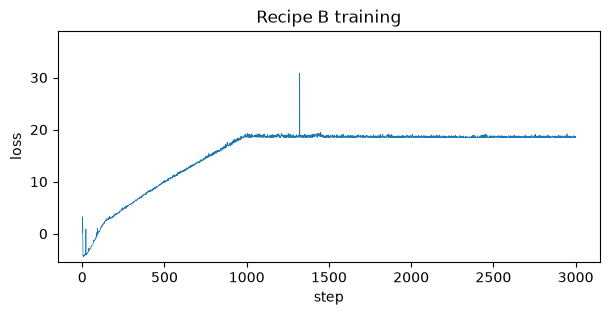

In [7]:
def train_recipe_b(target, n_iter=3000, seed=0, log_every=500):
    torch.manual_seed(seed)
    model = gm.make_spline_flow(4, n_layers=6, hidden=64, target=target, coupled=True)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_iter)
    losses = []
    t0 = time.time()
    for it in range(n_iter):
        beta = min(1.0, 0.01 + it / (n_iter / 3))
        loss = model.reverse_kld(num_samples=256, beta=beta)
        opt.zero_grad()
        if torch.isfinite(loss):
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            opt.step()
        sched.step()
        losses.append(loss.item())
        if (it + 1) % log_every == 0:
            print(f"step {it+1:5d}  beta {beta:.2f}  loss {np.mean(losses[-100:]):9.3f}   ({time.time()-t0:.0f}s)")
    model.eval()
    return model, losses

flow, losses = train_recipe_b(posterior)
plt.figure(figsize=(7, 3)); plt.plot(losses, lw=0.5); plt.ylim(np.percentile(losses, 1) - 2, np.percentile(losses[-1000:], 99) + 20)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Recipe B training"); plt.show()

## 6. Grade the flow

### 6a. Against the gold standard and the truth
Pairwise scatter of the four numbers: **blue = MCMC (answer key)**, **orange = flow**, **black star = hidden truth**.

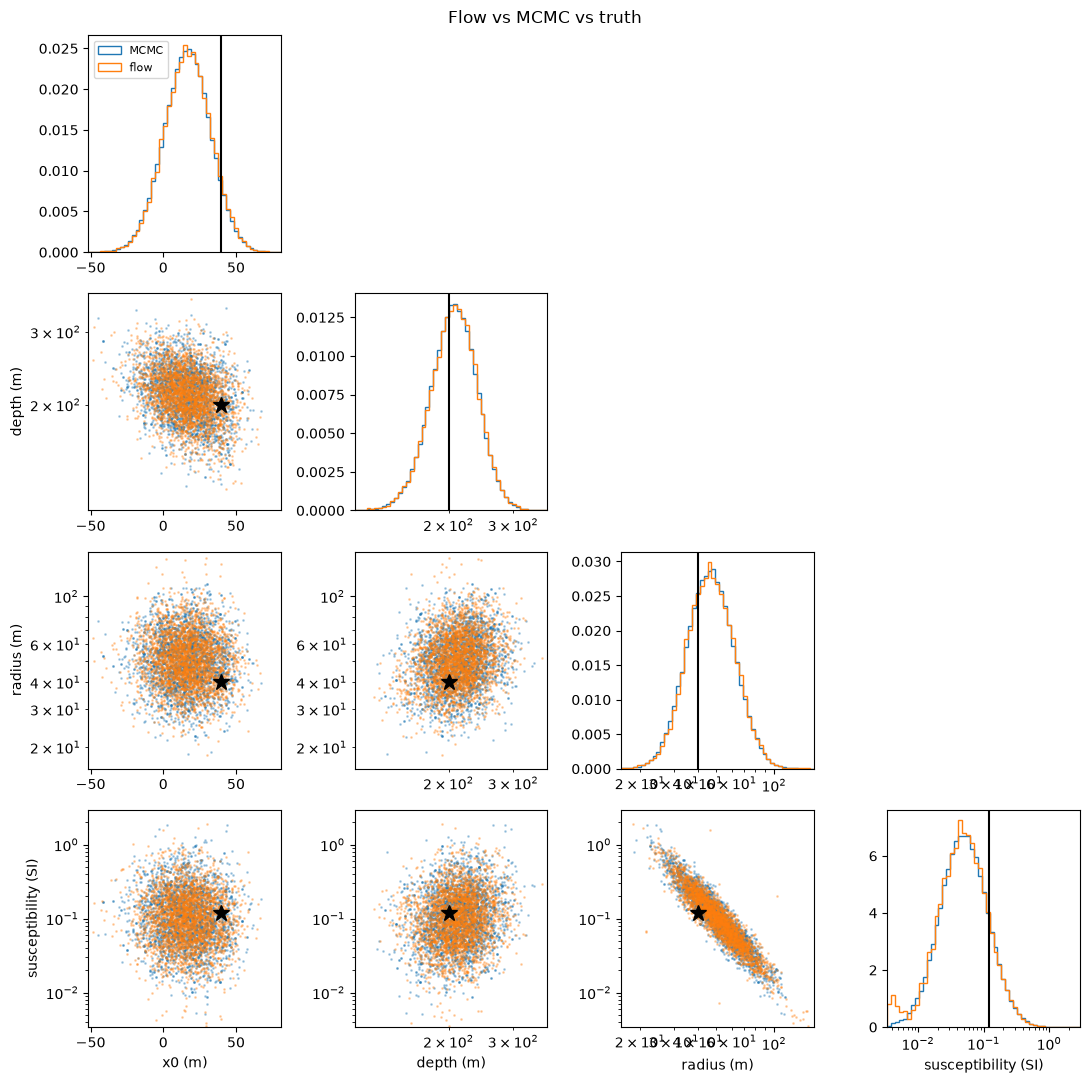

In [8]:
with torch.no_grad():
    theta_flow, log_q = flow.sample(20000)
P_flow, P_mcmc = gm.phys_matrix(theta_flow).numpy(), gm.phys_matrix(mcmc).numpy()
P_true = gm.phys_matrix(theta_true).numpy()[0]
LOG_AXES = [False, True, True, True]

def axis_limits(P, truth):
    """Zoom each axis to where the reference samples (first set) live, plus the truth, with some padding."""
    lims = []
    for i in range(P.shape[1]):
        lo, hi = np.quantile(P[:, i], [0.001, 0.999])
        lo, hi = min(lo, truth[i]), max(hi, truth[i])
        if LOG_AXES[i]:
            pad = (hi / lo) ** 0.15; lims.append((lo / pad, hi * pad))
        else:
            pad = 0.15 * (hi - lo); lims.append((lo - pad, hi + pad))
    return lims

def corner(sets, truth, names=gm.PARAM_NAMES, n=3000, title=""):
    k = len(names)
    lims = axis_limits(sets[0][1], truth)
    fig, axes = plt.subplots(k, k, figsize=(11, 11))
    for i in range(k):
        for j in range(k):
            a = axes[i, j]
            if j > i:
                a.axis("off"); continue
            for (label, P, c) in sets:
                if i == j:
                    lo, hi = lims[i]
                    bins = np.geomspace(lo, hi, 50) if LOG_AXES[i] else np.linspace(lo, hi, 50)
                    a.hist(P[:, i], bins=bins, density=True, histtype="step", color=c, label=label)
                else:
                    a.scatter(P[:n, j], P[:n, i], s=1, alpha=0.3, color=c)
            if i == j:
                a.axvline(truth[i], color="k")
            else:
                a.plot(truth[j], truth[i], "k*", ms=12)
                a.set_ylim(*lims[i])
            a.set_xlim(*lims[j])
            if LOG_AXES[j]: a.set_xscale("log")
            if LOG_AXES[i] and i != j: a.set_yscale("log")
            if i == k - 1: a.set_xlabel(names[j])
            if j == 0 and i != 0: a.set_ylabel(names[i])
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

corner([("MCMC", P_mcmc, "C0"), ("flow", P_flow, "C1")], P_true, title="Flow vs MCMC vs truth")

In [9]:
qs = torch.tensor([0.05, 0.5, 0.95])
print(f"{'':22s}{'5%':>22s}{'median':>22s}{'95%':>22s}     truth   inside flow 90%?")
truth_inside, quantile_gaps = [], []
for i, name in enumerate(gm.PARAM_NAMES):
    qf = torch.quantile(torch.tensor(P_flow[:, i]), qs).numpy()
    qm = torch.quantile(torch.tensor(P_mcmc[:, i]), qs).numpy()
    inside = qf[0] <= P_true[i] <= qf[2]
    truth_inside.append(inside)
    cells = "".join(f"{f:>10.3g} / {m:<9.3g}" for f, m in zip(qf, qm))
    print(f"{name:22s}{cells}  {P_true[i]:8.3g}   {inside}")
    # agreement measured in theta space, relative to MCMC spread
    tq_f = torch.quantile(theta_flow[:, i], qs); tq_m = torch.quantile(mcmc[:, i], qs)
    quantile_gaps.append(((tq_f - tq_m).abs().max() / mcmc[:, i].std()).item())
print("\n(each cell: flow / MCMC)")
print("worst quantile gap per parameter, in units of MCMC std:", [round(v, 3) for v in quantile_gaps])

                                          5%                median                   95%     truth   inside flow 90%?
x0 (m)                     -10.5 / -10.7          16.6 / 16.4           42.9 / 42.3             40   True
depth (m)                    165 / 165             211 / 211             265 / 265             200   True
radius (m)                  31.8 / 31.5           50.6 / 50.2           81.4 / 80.6             40   True
susceptibility (SI)       0.0246 / 0.0253       0.0982 / 0.1           0.377 / 0.394          0.12   True

(each cell: flow / MCMC)
worst quantile gap per parameter, in units of MCMC std: [0.039, 0.016, 0.037, 0.054]


### 6b. The flow grades itself (only possible because it's invertible)

For every flow sample we know **exactly** how dense the flow is there (`log q`, via the change-of-variables formula) and what the score is (`log p`).
If the flow were perfect, `p/q` would be the same for every sample. The **importance effective sample size** turns the spread of `p/q` into a number:
100% = perfect, a few % = the flow is missing something. No MCMC needed — this check works on real problems where there's no answer key.

In [10]:
with torch.no_grad():
    log_p = posterior.log_prob(theta_flow)
ess = gm.importance_ess(log_p, log_q)
print(f"importance ESS: {ess:.1%} of samples")

importance ESS: 98.4% of samples


**Stray samples.** A handful of flow samples land far from anywhere MCMC went (e.g. a lump 800 m deep).
These are the "thin bridges" from Lesson 1: the flow can't put *exactly zero* probability anywhere.
The importance weights `p/q` already know they're junk — they're far smaller than typical — so you can either reweight by `p/q` or just be aware a tiny fraction of pictures are silly.

In [11]:
outside = ((theta_flow < mcmc.min(0).values) | (theta_flow > mcmc.max(0).values)).any(1)
log_w = (log_p - log_q)
rel_w = (log_w - log_w.median()).exp()
print(f"{outside.sum().item()} of {len(theta_flow):,} flow samples ({outside.double().mean().item():.2%}) lie outside everywhere MCMC visited")
print(f"their importance weight relative to a typical sample: median {rel_w[outside].median().item():.1e}")

57 of 20,000 flow samples (0.29%) lie outside everywhere MCMC visited
their importance weight relative to a typical sample: median 2.1e-18


## 7. The pictures

Each flow sample *is* a picture of the underground. Here are 80 of them as circles in a cross-section, with the true lump in black.

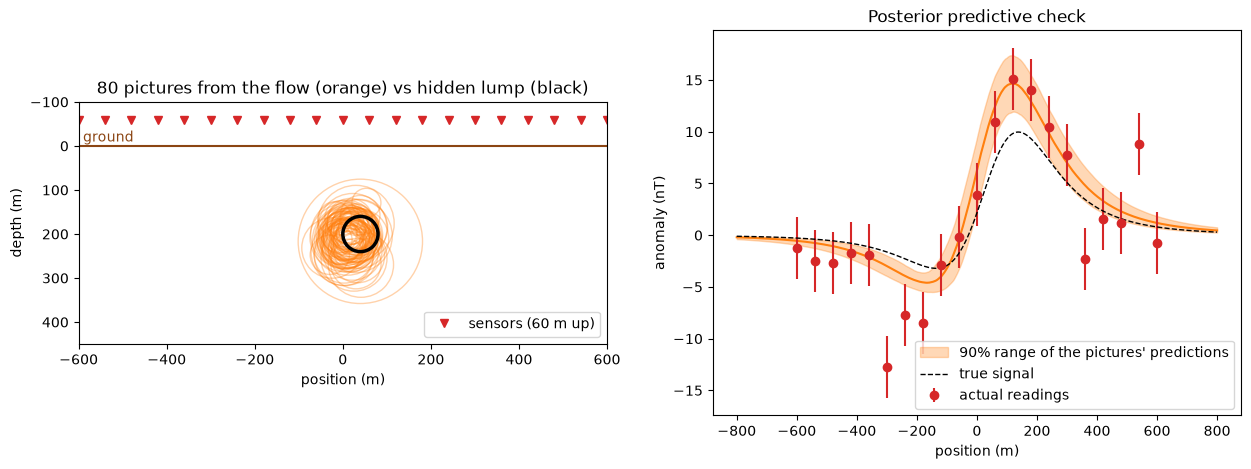

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for k in range(80):
    x0, d, r, _ = P_flow[k]
    ax[0].add_patch(Circle((x0, d), r, fill=False, color="C1", alpha=0.35))
ax[0].add_patch(Circle((TRUE["x0"], TRUE["depth"]), TRUE["radius"], fill=False, color="k", lw=2.5))
ax[0].plot(x_sensors, np.full(len(x_sensors), -60), "v", color="C3", label="sensors (60 m up)")
ax[0].axhline(0, color="saddlebrown"); ax[0].text(-590, -10, "ground", color="saddlebrown")
ax[0].set_xlim(-600, 600); ax[0].set_ylim(450, -100); ax[0].set_aspect("equal")
ax[0].set_xlabel("position (m)"); ax[0].set_ylabel("depth (m)"); ax[0].legend(loc="lower right")
ax[0].set_title("80 pictures from the flow (orange) vs hidden lump (black)")

# Posterior predictive: what readings would each picture produce?
with torch.no_grad():
    pred = gm.predict(theta_flow[:2000], xs_dense).numpy()
lo, mid, hi = np.percentile(pred, [5, 50, 95], axis=0)
ax[1].fill_between(xs_dense, lo, hi, color="C1", alpha=0.3, label="90% range of the pictures' predictions")
ax[1].plot(xs_dense, mid, color="C1")
ax[1].errorbar(x_sensors, readings, yerr=NOISE, fmt="o", color="C3", label="actual readings")
ax[1].plot(xs_dense, gm.predict(theta_true, xs_dense)[0], "k--", lw=1, label="true signal")
ax[1].set_xlabel("position (m)"); ax[1].set_ylabel("anomaly (nT)"); ax[1].legend()
ax[1].set_title("Posterior predictive check")
plt.show()

Left: the pictures cluster around the hidden lump; their spread *is* the uncertainty.

Right: the band covers the readings well — that's what a passing posterior predictive check looks like.
Notice the **true signal (dashed) sits a little below the band near the peak**: the noise happened to push several readings up,
and the posterior honestly followed the data. A 90% range is *supposed* to miss about 10% of the time — Lesson 3 measures whether it really does.

### What the readings can't tell us
Left: radius vs susceptibility. The data only pin down `radius³ × chi`, so the samples lie along a curve — and *where along the curve* is decided by the **prior**, not the data.
Right: depth vs that combined "magnet strength". Deeper lumps need to be stronger to make the same bump — the depth/size trade-off from the conversation.

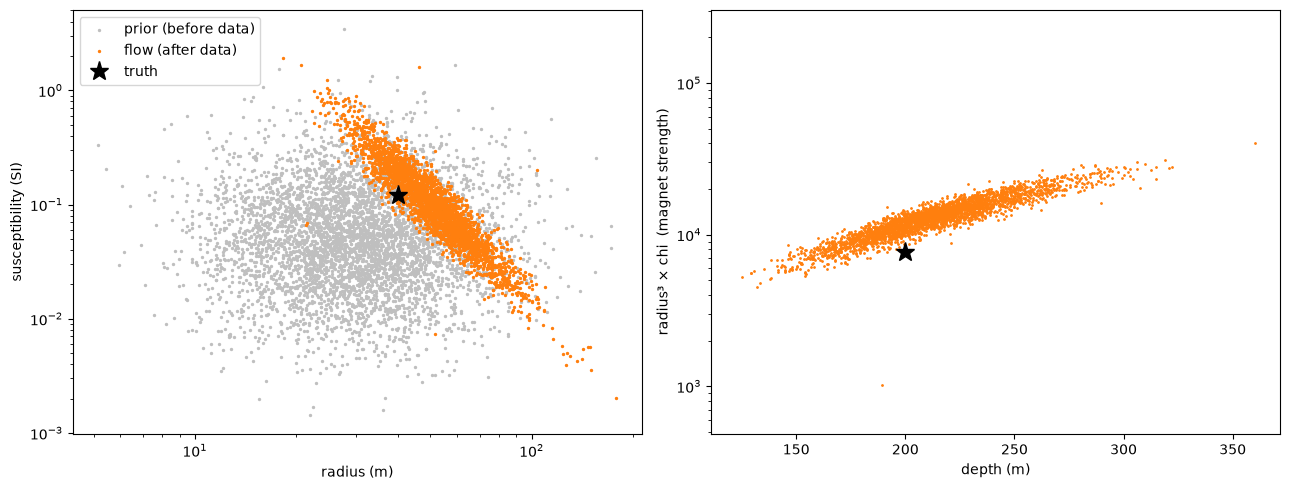

In [13]:
strength = P_flow[:, 2] ** 3 * P_flow[:, 3]
prior_theta = torch.randn(5000, 4)
P_prior = gm.phys_matrix(prior_theta).numpy()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(P_prior[:, 2], P_prior[:, 3], s=2, color="0.75", label="prior (before data)")
ax[0].scatter(P_flow[:3000, 2], P_flow[:3000, 3], s=2, color="C1", label="flow (after data)")
ax[0].plot(TRUE["radius"], TRUE["chi"], "k*", ms=14, label="truth")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("radius (m)"); ax[0].set_ylabel("susceptibility (SI)")
ax[0].legend()
ax[1].set_xlim(*axis_limits(P_mcmc, P_true)[1])
ax[1].scatter(P_flow[:3000, 1], strength[:3000], s=1, color="C1")
ax[1].plot(TRUE["depth"], TRUE["radius"] ** 3 * TRUE["chi"], "k*", ms=14)
ax[1].set_yscale("log"); ax[1].set_xlabel("depth (m)"); ax[1].set_ylabel("radius³ × chi  (magnet strength)")
plt.tight_layout(); plt.show()

## 8. Experiment: lie about the noise

Suppose we believe the spec sheet's **0.6 nT**, but real-world noise is **3 nT** (wind, terrain, the plane itself).
Same readings, same flow recipe — only the score's `noise` changes.

step  1000  beta 1.00  loss   347.475   (48s)


step  2000  beta 1.00  loss   359.581   (97s)


step  3000  beta 1.00  loss   359.889   (145s)


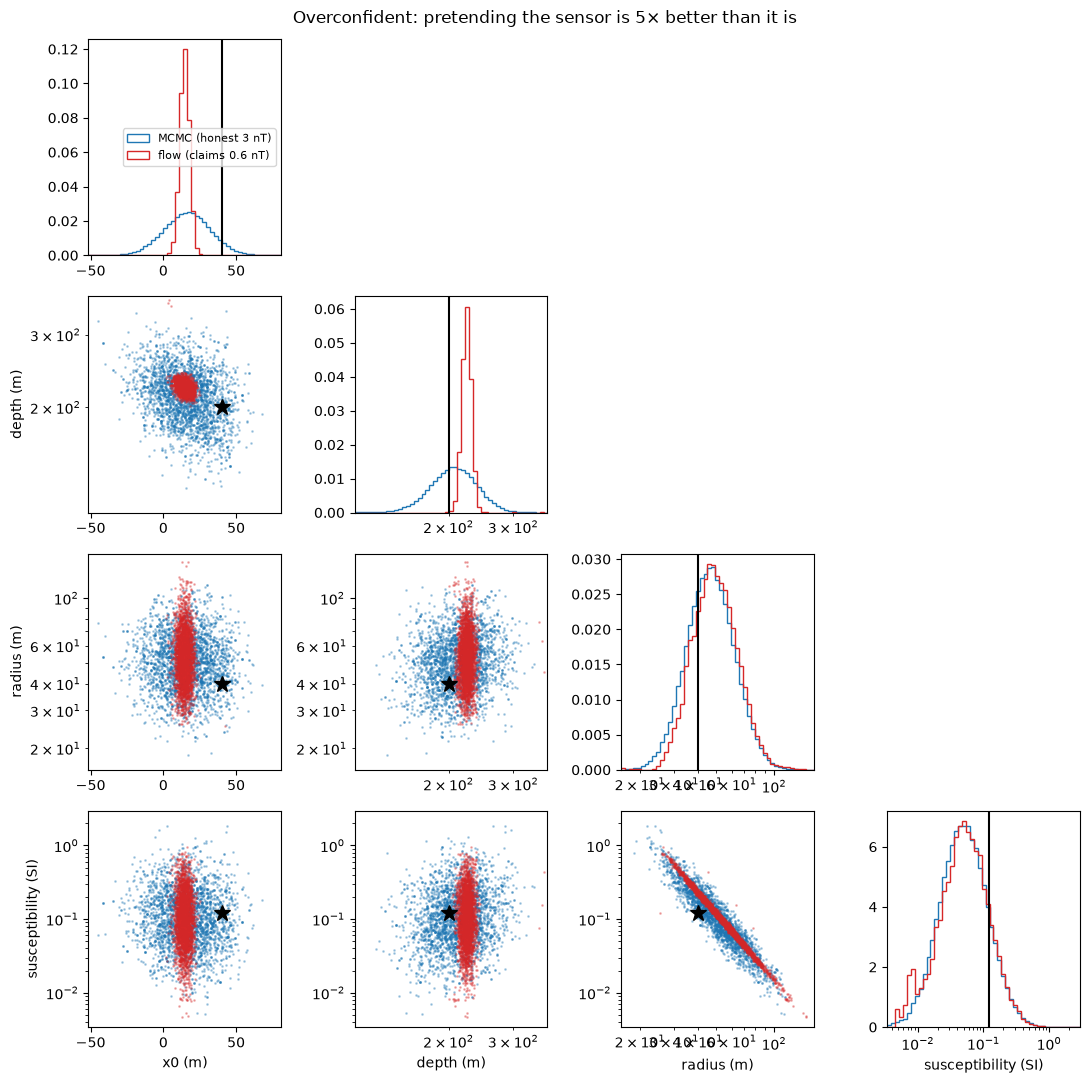

x0 (m)                 90% range       9.1 … 19.6      truth       40  inside: False
depth (m)              90% range       213 … 234       truth      200  inside: False
radius (m)             90% range      34.1 … 83        truth       40  inside: True
susceptibility (SI)    90% range    0.0259 … 0.369     truth     0.12  inside: True


In [14]:
posterior_liar = gm.SpherePosterior(x_sensors, readings, noise=0.6)
flow_liar, _ = train_recipe_b(posterior_liar, log_every=1000)
with torch.no_grad():
    theta_liar, _ = flow_liar.sample(20000)
P_liar = gm.phys_matrix(theta_liar).numpy()
corner([("MCMC (honest 3 nT)", P_mcmc, "C0"), ("flow (claims 0.6 nT)", P_liar, "C3")], P_true,
       title="Overconfident: pretending the sensor is 5× better than it is")
liar_inside = []
for i, name in enumerate(gm.PARAM_NAMES):
    lo_, hi_ = np.percentile(P_liar[:, i], [5, 95])
    liar_inside.append(lo_ <= P_true[i] <= hi_)
    print(f"{name:22s} 90% range {lo_:9.3g} … {hi_:<9.3g} truth {P_true[i]:8.3g}  inside: {liar_inside[-1]}")

Position and depth become **tight and wrong** — the truth falls outside the 90% range.
Radius and susceptibility still look fine, but only because the readings never constrained them separately in the first place: their spread comes from the prior, which we didn't lie about.

**How would you catch this without knowing the truth?** Compare the leftovers (readings − predictions) with the noise you *claimed*.
If the noise level is honest, the leftovers should be about 1 noise-unit in size (a normalised misfit near 1.0).
Much bigger than 1 means your noise claim is too optimistic — or the physics is wrong.

In [15]:
def normalised_misfit(theta, post):
    """RMS of (reading - prediction) / claimed noise, for the best-scoring picture."""
    with torch.no_grad():
        best = theta[post.log_prob(theta).argmax()][None]
        resid = post.readings - gm.predict(best, post.x_sensors)[0]
    return (resid / post.noise).pow(2).mean().sqrt().item()

misfit_honest = normalised_misfit(theta_flow, posterior)
misfit_liar = normalised_misfit(theta_liar, posterior_liar)
print(f"normalised misfit with honest 3 nT:   {misfit_honest:.2f}   (≈1 → consistent)")
print(f"normalised misfit claiming 0.6 nT:   {misfit_liar:.2f}   (≫1 → red flag: noise claim or physics is wrong)")

normalised misfit with honest 3 nT:   1.15   (≈1 → consistent)
normalised misfit claiming 0.6 nT:   5.76   (≫1 → red flag: noise claim or physics is wrong)


## Report card

In [16]:
results = {
    "MCMC chains agree (R-hat < 1.01)": bool((rhat < 1.01).all()),
    "flow matches MCMC (all 5/50/95% quantiles within 0.2 MCMC-std)": max(quantile_gaps) < 0.2,
    "flow self-check: importance ESS > 30%": ess > 0.30,
    "hidden truth inside the flow's 90% range for all 4 numbers": all(truth_inside),
    "honest noise: normalised misfit between 0.6 and 1.5": 0.6 < misfit_honest < 1.5,
    "lying about noise is detectable: misfit > 2": misfit_liar > 2,
}
for k, v in results.items():
    print(("PASS  " if v else "FAIL  ") + k)
print(f"\n(for interest) overconfident flow kept the truth inside its 90% range for {sum(liar_inside)}/4 numbers")
assert all(results.values()), "some checks failed"

PASS  MCMC chains agree (R-hat < 1.01)
PASS  flow matches MCMC (all 5/50/95% quantiles within 0.2 MCMC-std)
PASS  flow self-check: importance ESS > 30%
PASS  hidden truth inside the flow's 90% range for all 4 numbers
PASS  honest noise: normalised misfit between 0.6 and 1.5
PASS  lying about noise is detectable: misfit > 2

(for interest) overconfident flow kept the truth inside its 90% range for 2/4 numbers


## Take-aways
- Recipe B needed **no examples** — just physics + a noise level + a prior.
- The flow matched the MCMC answer key, and its importance ESS let it **grade itself** — the payoff of exact densities from invertibility.
- The pictures show *what is known* (position, roughly depth) and *what isn't* (radius vs susceptibility — the prior decides).
- A dishonest noise level makes tight, wrong answers. The normalised-misfit check catches it **without** knowing the truth.

**Things to try:** move `TRUE["depth"]` to 350 m; cut `x_sensors` to 11 points; set `n_layers=1` in `train_recipe_b` and watch ESS drop.

**Next lesson:** train *once* on thousands of simulated surveys (a conditional flow, Recipe A), then get pictures for a new survey instantly — and test whether its 90% ranges really contain the truth 90% of the time.